# State of the art: smooth run-offs against the run speeds of 2023, and the 2019 sensitivity analysis of the ECB

**Question:** Is the smooth run-off of the ECB's 2019 liquidity stress test, which the product follows, fast enough for the runs of 2023, and how do the survival periods of the product compare with the ones the ECB reported for 103 banks?

- **Level:** 3, State of the art
- **Prerequisites:** notebooks 01 to 06 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- place the liquidity stress of the product in the state of the art that the research found: the ECB's liquidity stress test of 2019, the Basel principles, the report on the 2023 turmoil and the theory of bank runs;
- compare the smooth run-off of the LiST with the fast run on the same balance sheet, in survival periods and in the share of deposits lost at the horizon of each run of 2023;
- run the third severity of the LiST, Baseline, which the product does not use, and compare the 30-day LCR outflow and the survival periods with the speed of the 2023 runs and with the medians of the ECB;
- say what this comparison does and does not show about the product.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Four committed documents of case C16 (real FDIC call-report aggregates of the bank that failed on 2023-03-10 up to 2022-12-31, synthetic behaviour and deposits, licence class `mirror-allowed`): the three path variants `list-adverse.json`, `list-extreme.json` and `fast-run.json`, and `lcr-standard.json`, all in `data/derived/C16/`. The observed runs are Table A.1 of the BCBS report on the 2023 turmoil, held by the engine as `TABLE_A1` within the BIS limited-extract terms.

The fast run is calibrated on the rows dated before 2023 only and scored on the 2023 rows (notebook 04); every modelled share below is the cumulative outflow of the segments of the document over the deposit base of the model. Amounts are in USD thousands.

In [2]:
# Load the four committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
documents = {}
for name in ("list-adverse", "list-extreme", "fast-run", "lcr-standard"):
    path = ROOT / "data" / "derived" / "C16" / f"{name}.json"
    documents[name] = json.loads(path.read_text(encoding="utf-8"))
    baked = documents[name]["provenance"]["riskvalidation_version"]
    print(name, "| baked by riskvalidation", baked, "| installed", rv.__version__)

variants = {name: documents[name] for name in ("list-adverse", "list-extreme", "fast-run")}

list-adverse | baked by riskvalidation 1.0.1 | installed 1.0.1
list-extreme | baked by riskvalidation 1.0.1 | installed 1.0.1
fast-run | baked by riskvalidation 1.0.1 | installed 1.0.1
lcr-standard | baked by riskvalidation 1.0.1 | installed 1.0.1


## Method

### Step 1: the survival period of the three variants

The comparison needs one measure that all variants share: the survival period, the first day on which the net liquidity position turns negative, with "survives the horizon" when it never does (notebook 01). The three variants differ in the speed of the run-off: LiST Adverse and Extreme use the smooth daily rates of the ECB's tables, and the fast run puts on the uninsured corporate segment the rate calibrated on the runs before 2023, over an acute horizon of 5 days. The next cell computes the survival period and the minimum NLP of each variant from its committed NLP series with the engine.

In [3]:
# The survival period and the minimum NLP of each variant, from its committed NLP series, with the engine
from riskvalidation.liquidity.ladder import minimum_nlp, survival_period

print(f"{'variant':14s}{'horizon':>9s}{'survival':>24s}{'minimum NLP (USD bn)':>24s}{'day':>6s}")
for name, document in variants.items():
    nlp = np.array(document["outputs"]["path"]["ladder"]["nlp"])
    result = survival_period(nlp)
    low, low_day = minimum_nlp(nlp)
    survival_text = "survives the horizon" if result.survives else f"day {result.day}"
    print(f"{name:14s}{result.horizon:9d}{survival_text:>24s}{low / 1e6:24.2f}{low_day:6d}")

variant         horizon                survival    minimum NLP (USD bn)   day
list-adverse        125                  day 62                  -40.97   125
list-extreme        125                  day 41                  -65.65   125
fast-run              5    survives the horizon                   13.80     1


### Step 2: the share of deposits lost at the horizon of each run

The survival period depends on the CBC and on the outflows together. To compare the speed of the run-off with what happened we use the outflow alone: for a run that lost a share $F_i$ of its deposits in $n_i$ days (row $i$ of Table A.1) the model's counterpart is the cumulative outflow of the segments over the same $n_i$ days, as a share of the deposit base $B$:

$$\hat F_i = \frac{1}{B} \sum_{s} \sum_{d \le n_i} O_s(d), \qquad \text{error}_i = F_i - \hat F_i$$

A row whose horizon exceeds the ladder of a variant cannot be scored on it (the fast run has 5 days). The next cell computes every modelled share from the opening balance and the daily rates of the committed segments with the engine, and prints the rows from the shortest to the longest horizon. A positive error means the model loses less than the run did.

In [4]:
# The modelled share at the horizon of every run of Table A.1, for each variant, from the engine's outflows
from riskvalidation.liquidity.ladder import behavioural_outflows
from riskvalidation.liquidity.runoff import TABLE_A1

modelled = {}
for name, document in variants.items():
    segments = document["outputs"]["path"]["ladder"]["segments"]
    opening = np.array([s["opening_balance"] for s in segments])
    horizon = len(segments[0]["outflows"])
    rates = np.array([s["daily_rates"] or np.ones(horizon) for s in segments])
    base = document["outputs"]["scoring"]["model_deposit_base"]
    outflow = np.cumsum(behavioural_outflows(opening, rates).sum(axis=0))
    shares = {}
    for run in TABLE_A1:
        shares[run.row_id] = None if run.days > len(outflow) else outflow[run.days - 1] / base
    modelled[name] = shares

print(f"{'bank':16s}{'year':>6s}{'days':>6s}{'observed':>10s}{'Adverse':>10s}{'Extreme':>10s}{'fast run':>10s}")
for run in sorted(TABLE_A1, key=lambda r: (r.days, r.year)):
    cells = ["-" if modelled[n][run.row_id] is None else f"{modelled[n][run.row_id]:.4f}" for n in modelled]
    left = f"{run.bank:16s}{run.year:6d}{run.days:6d}{run.outflow_share:10.2f}"
    print(left + f"{cells[0]:>10s}{cells[1]:>10s}{cells[2]:>10s}")

bank              year  days  observed   Adverse   Extreme  fast run
SVB UK            2023     1      0.30    0.0854    0.0887    0.1263
Signature         2023     1      0.20    0.0854    0.0887    0.1263
SVB               2023     2      0.85    0.0915    0.0980    0.1708
Northern Rock     2007     4      0.20    0.1036    0.1164    0.2528
WaMu              2008    10      0.10    0.1390    0.1694         -
IndyMac           2008    14      0.08    0.1618    0.2029         -
Icesave           2008    75      0.20    0.4425    0.5722         -
First Republic    2023    90      0.57    0.4955    0.6323         -
Credit Suisse     2023    90      0.21    0.4955    0.6323         -


The next cell draws the modelled share against the observed share of each run that a variant can score, on logarithmic axes: a point on the diagonal is a model that loses what the run lost, a point under it a model that loses less.

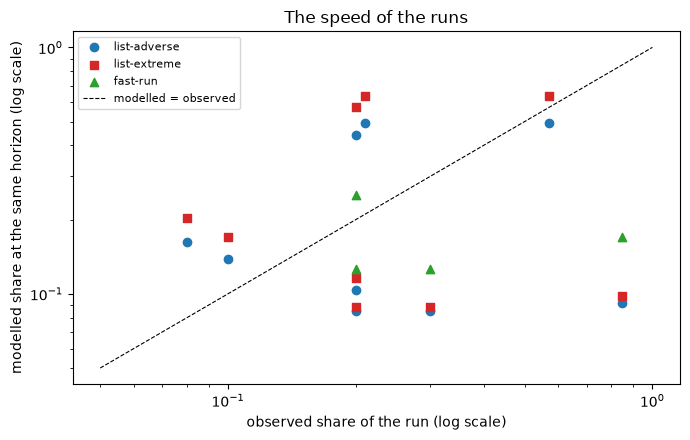

In [5]:
# Draw the modelled against the observed share of each run, for the three variants
fig, ax = plt.subplots(figsize=(7, 4.5))
for (name, shares), color, marker in zip(modelled.items(), ("tab:blue", "tab:red", "tab:green"), ("o", "s", "^")):
    points = [(run.outflow_share, shares[run.row_id]) for run in TABLE_A1 if shares[run.row_id] is not None]
    ax.scatter([p[0] for p in points], [p[1] for p in points], color=color, marker=marker, label=name)
ax.plot([0.05, 1.0], [0.05, 1.0], color="black", linestyle="--", linewidth=0.8, label="modelled = observed")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("observed share of the run (log scale)")
ax.set_ylabel("modelled share at the same horizon (log scale)")
ax.set_title("The speed of the runs")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The points of the fast runs, those of one and two days at the right of the plot, sit under the diagonal, which means that the model loses less than the run did. The three variants lose 0.0854, 0.0887 and 0.1263 of the deposit base on the runs of one day (SVB UK, 0.30, and Signature, 0.20) and 0.0915, 0.0980 and 0.1708 on the two days of SVB (0.85). The fast run, calibrated before 2023, comes closest and still reaches about a fifth of SVB's loss. The slow runs of 2008 and Credit Suisse lie above the diagonal for the smooth variants, that is, those variants cover them, while Northern Rock (0.20 in 4 days, 0.2528 for the fast run) is covered only by the fast run and First Republic (0.57 in 90 days) only by the Extreme variant. The figure compares shares at the horizon of each run and does not say anything about the CBC that stands against them.

## State of the art

What the research found, with the source of each point. Only the sources listed in the SDD are cited.

- **The ECB's liquidity stress test of 2019 (LiST).** It defines the net liquidity position, the survival period and the cliff effect, and runs open-maturity deposits off at constant daily compounding rates on relevant days; in its results 103 banks reported a median survival period of 176 days under the Adverse shock and 122 days under the Extreme shock, and the shocks are idiosyncratic only (ECB, 2019, methodological note and results annex).
- **The Basel principles.** Principle 10 asks banks to stress their liquidity in a variety of short-term and protracted, institution-specific and market-wide scenarios, individually and in combination (BCBS, 2008).
- **The 2023 turmoil.** The BCBS report documents the speed of the runs of 2023 against earlier ones in Table A.1 (SVB 85% in 2 days; First Republic 57% in 90 days) and raises as open questions metrics such as a five-day forward counterbalancing capacity, the survival period and a liquidity metric without run-off assumptions (BCBS, 2023). The Federal Reserve's review found outflows of more than 40 billion USD on 9 March, with management expecting 100 billion more the next day, and that the bank's internal liquidity stress test relied on peer benchmarks that were not comparable (Federal Reserve, 2023).
- **Theory and the digital run.** Diamond and Dybvig (1983) show that a demand-deposit contract has a good equilibrium and a run equilibrium, and that deposit insurance removes the second; the uninsured share is therefore a run-risk driver, not a calibrated model. Cookson et al. (2026) relate exposure to social media to the stock losses of banks in the run on Silicon Valley Bank; the product does not model it.
- **Unrealised losses.** Marking US bank assets to market after the rate rise of 2022 gives large unrealised losses, and these reduce the effective CBC and can trigger runs (Jiang et al., 2024; notebook 03).
- **The model ladder.** The research dossier orders the models of a liquidity stress from a static contractual ladder to a behavioural ladder, a scenario engine, run-speed calibration with sensitivities, and reverse liquidity stress; it found no mature open-source engine for the whole ladder (UNVERIFIED beyond the dossier's search). The product implements the five rungs; funds transfer pricing is not implemented.

The three steps below run the engine on the data of the case against these points: the third severity of the LiST, which the product does not use; the speed of SVB against the tables and the LCR; and the survival periods of the case against the medians that the ECB reported for 103 banks.

### Step 3: the LiST Baseline severity

The 2019 test has three severities, and the product runs two of them as variants. The engine holds the third, Baseline, with the same classes (ECB, 2019, Table 3.3). The next cell composes it on the segments and the ladder of the LiST Adverse document and computes its survival period and its minimum NLP.

In [6]:
# The LiST Baseline severity on the segments and the ladder of the LiST Adverse document
from riskvalidation.liquidity.ladder import net_liquidity_position
from riskvalidation.liquidity.scenarios import compose_scenario, list_scenario

document = variants["list-adverse"]["outputs"]
lad = document["path"]["ladder"]
row = next(r for r in document["conventions"]["variant_scenarios"]["rows"] if r["variant"] == "list-adverse")
segments = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
args = (row["scenario_family"], row["phase"], list_scenario("baseline"))
scenario = compose_scenario(*args, segments, row["horizon_days"])
contractual = np.sum([c["amounts"] for c in lad["other_outflows"]], axis=0)
inflows = np.sum([c["amounts"] for c in lad["inflows"]], axis=0)
total_outflows = scenario.outflows().sum(axis=0) + contractual
baseline_nlp = net_liquidity_position(np.array(lad["cbc_total"]), total_outflows, inflows)
baseline = survival_period(baseline_nlp)
low, low_day = minimum_nlp(baseline_nlp)

print("survives the horizon:", baseline.survives, "| horizon (days):", baseline.horizon)
print("minimum NLP (USD billions) and its day:", round(low / 1e6, 2), low_day)

survives the horizon: True | horizon (days): 125
minimum NLP (USD billions) and its day: 22.06 1


Under Baseline the bank survives the whole horizon, and its NLP never falls below 22.06 billion USD (on day 1, when the financial segment leaves in full): the open-maturity classes of the segments have a zero rate, so the only outflows are that segment and the contractual ones. The severity is not a stress for this balance sheet, which is why the product keeps Adverse and Extreme; it is a floor of the family of tables, with no run in it.

### Step 4: how much faster was 2023 than the tables

Putting the runs and the tables on the same scale takes the implied daily rate $q = 1-(1-F)^{1/n}$ (notebook 02). The rate of Silicon Valley Bank (85% in 2 days; Federal Reserve, 2023) against the rate that LiST Adverse and Extreme give to the uninsured corporate class, and against the highest 30-day deposit outflow of the LCR (40% in 30 days, the top of the range in Table A.1), shows the distance. The next cell computes the rates and the ratios.

In [7]:
# The implied daily rate of SVB against the LiST rates of the uninsured corporate class and the top of the LCR range
from riskvalidation.liquidity.runoff import LIST_PARAMETERS, TABLE_A1_LCR_RANGE, daily_rate_from_cumulative

svb = next(run for run in TABLE_A1 if run.row_id == "svb-2023")
corporate = "non-operational-non-financial-corporates"
rates = {severity: LIST_PARAMETERS[severity]["open_maturity"][corporate] for severity in ("adverse", "extreme")}
low_share, high_share, lcr_days = TABLE_A1_LCR_RANGE
rates["lcr top"] = daily_rate_from_cumulative(high_share, lcr_days)
rates["svb"] = daily_rate_from_cumulative(svb.outflow_share, svb.days)

print("implied daily rate of SVB (85 percent in 2 days):", round(rates["svb"], 6))
for name in ("adverse", "extreme", "lcr top"):
    print(f"{name:8s} | daily rate: {rates[name]:.8f} | SVB over it: {rates['svb'] / rates[name]:.1f}")
lcr = documents["lcr-standard"]["outputs"]["lcr"]
print("LCR of the document:", round(lcr["ratio"], 4))
print("net outflow of the LCR over its stock of HQLA:", round(lcr["net_outflows"] / lcr["hqla"]["hqla"], 4))

implied daily rate of SVB (85 percent in 2 days): 0.612702
adverse  | daily rate: 0.00688541 | SVB over it: 89.0
extreme  | daily rate: 0.01065229 | SVB over it: 57.5
lcr top  | daily rate: 0.01688337 | SVB over it: 36.3
LCR of the document: 0.4726
net outflow of the LCR over its stock of HQLA: 2.1158


The next cell draws the four daily rates on a logarithmic axis: the two LiST rates for the uninsured corporate class, the top of the LCR range and the rate of SVB.

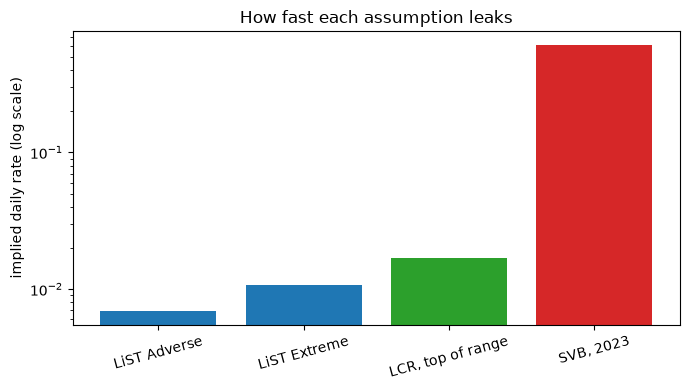

In [8]:
# Draw the daily rates of the LiST tables, the LCR range and SVB on a logarithmic axis
labels = ["LiST Adverse", "LiST Extreme", "LCR, top of range", "SVB, 2023"]
values = [rates["adverse"], rates["extreme"], rates["lcr top"], rates["svb"]]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(labels, values, color=["tab:blue", "tab:blue", "tab:green", "tab:red"])
ax.set_yscale("log")
ax.set_ylabel("implied daily rate (log scale)")
ax.set_title("How fast each assumption leaks")
ax.tick_params(axis="x", labelrotation=15)
fig.tight_layout()
plt.show()

Each bar is roughly an order of magnitude above the previous one. The LiST rates for the uninsured corporate class, 0.00688541 and 0.01065229 a day, sit at the bottom; the top of the LCR range, 0.016883, is the next step; and the rate of SVB, 0.612702, is 89.0 times the Adverse rate, 57.5 times the Extreme one and 36.3 times the LCR rate. The net outflow of the LCR is 2.1158 times the stock of HQLA, so even the faster of the regulatory assumptions leaves the bank short, but not at the speed of 2023. The bars compare rates implied by one run each: SVB is a single observation.

### Step 5: the survival periods against the medians of the 2019 test

The next cell sets the survival periods of the product beside the medians of the 2019 test. The medians are the ECB's own figures, entered here as constants with their source, because they do not belong to any committed document. They describe 103 real banks, and this case is one synthetic-behaviour bank, so the comparison shows the order of magnitude of the method, not a ranking.

In [9]:
# The survival periods of the product beside the medians of the ECB test of 2019 (103 banks, results annex)
LIST_2019_MEDIAN = {"adverse": 176, "extreme": 122}  # median reported survival period in days, ECB results annex

ours = {}
for severity, name in (("adverse", "list-adverse"), ("extreme", "list-extreme")):
    nlp = np.array(variants[name]["outputs"]["path"]["ladder"]["nlp"])
    ours[severity] = survival_period(nlp).day
    median = LIST_2019_MEDIAN[severity]
    print(f"LiST {severity:8s} | this case (days): {ours[severity]} | median of the 103 banks (days): {median}")
    print(f"   ratio: {ours[severity] / LIST_2019_MEDIAN[severity]:.2f}")

LiST adverse  | this case (days): 62 | median of the 103 banks (days): 176
   ratio: 0.35
LiST extreme  | this case (days): 41 | median of the 103 banks (days): 122
   ratio: 0.34


The next cell draws the survival periods of this case against the medians of the 2019 test.

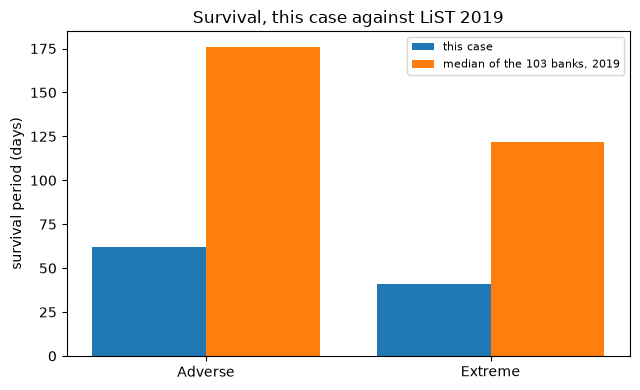

In [10]:
# Draw the survival periods of this case against the medians of the 2019 test
positions = np.arange(2)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(positions - 0.2, [ours["adverse"], ours["extreme"]], width=0.4, label="this case")
medians = [LIST_2019_MEDIAN["adverse"], LIST_2019_MEDIAN["extreme"]]
ax.bar(positions + 0.2, medians, width=0.4, label="median of the 103 banks, 2019")
ax.set_xticks(positions)
ax.set_xticklabels(["Adverse", "Extreme"])
ax.set_ylabel("survival period (days)")
ax.set_title("Survival, this case against LiST 2019")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

In both severities the case lasts about a third of what the median bank of the 2019 sample reported: 62 days against 176 under Adverse and 41 against 122 under Extreme, ratios of 0.35 and 0.34. The two ratios are almost equal, so the shape of the response to severity is the same even though the level differs. The reason is the balance sheet, not the method: the case has a large uninsured corporate base and a CBC that covers only part of it, and the 103 banks are real balance sheets with their own deposits and assets. The figure says that the same method gives survival periods of the order of months; it does not say that the bank ranks below the sample.

## Results

**Answer:** No, the smooth run-off is too slow for the runs of 2023. On the runs of one and two days the three variants lose 0.0854 to 0.1263 of the deposit base where SVB UK and Signature lost 0.30 and 0.20, and 0.0915 to 0.1708 where SVB lost 0.85. The implied daily rate of SVB, 0.612702, is 89.0 times the rate that LiST Adverse gives to the uninsured corporate class and 36.3 times the top of the LCR deposit range. Against the 2019 test the survival periods of this case, 62 and 41 days, are 0.35 and 0.34 of the medians of 103 banks (176 and 122 days), so the method gives months of survival and the balance sheet explains the level.

- **Survival.** The NLP of LiST Adverse turns negative on day 62 and that of Extreme on day 41, both with their minimum on day 125 (-40.97 and -65.65 billion USD); the fast run survives its 5-day horizon, with a minimum of 13.80 billion on day 1. Under the Baseline severity, which the product does not use, the bank survives the horizon and its minimum NLP is 22.06 billion on day 1.
- **Speed at the horizon of each run.** On the runs of one and two days the three variants lose far less than the runs did: 0.0854, 0.0887 and 0.1263 against 0.30 (SVB UK) and 0.20 (Signature), and 0.0915, 0.0980 and 0.1708 against 0.85 (SVB). The fast run, calibrated before 2023, is closer but still about a fifth of SVB's loss. At 90 days the picture changes: Adverse (0.4955) is under First Republic's 0.57 and Extreme (0.6323) is over it, and both are over Credit Suisse's 0.21; the slow runs of 2008 (Icesave, IndyMac, WaMu) are all covered with room to spare, while Northern Rock (0.20 in 4 days against 0.1036 and 0.1164) is not. The smooth rates are conservative for slow runs and far too slow for fast ones.
- **How much faster.** The implied daily rate of SVB, 0.612702, is 89.0 times the rate that LiST Adverse gives to the uninsured corporate class and 57.5 times that of Extreme, and 36.3 times the daily rate at the top of the LCR deposit range (40% in 30 days, 0.016883). The net outflow of the LCR of the document (0.4726) is 2.1158 times its stock of HQLA.
- **Against the state of the art.** The survival periods of this case, 62 and 41 days, are about a third of the medians of the 2019 test, 176 and 122 days (ratios of 0.35 and 0.34). The 103 banks are real balance sheets with their own deposits and assets, and this case is one bank with synthetic behaviour, so the ratio says that the same method gives survival periods of the order of months, not that the bank ranks below the sample.

What this comparison does not show: that the product's fast run is a forecast (it is a labelled calibration on runs before 2023), that the bank would have survived or failed in these numbers (its behaviour is synthetic), or that the LiST is wrong (it answers the question it was designed for: a slow, idiosyncratic leak over six months).

## Summary

- The smooth LiST run-off and the fast run are two answers to two questions; on the same balance sheet they differ by orders of magnitude in the speed they assume.
- Scored against the runs of 2023, the smooth variants lose far less than the runs of one and two days (SVB UK, Signature, SVB) and are conservative for the slow runs of 2008; the fast run, calibrated only on earlier runs, improves on them and still loses about a fifth of what SVB lost.
- The 30-day LCR outflow is faster than the smooth LiST rates but far slower than the runs of 2023, and the third LiST severity, Baseline, is no stress for this balance sheet.
- The product follows the ECB's method and adds what the dossier lists as the rest of the ladder; it does not claim a forecast.

**What to try next.** Change the target of the comparison in step 4 to the run of First Republic (57% in 90 days) and see how far its daily rate is from the LiST tables; then continue with notebook 08, which turns the distance to the 2023 runs into a number.

## References

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, results annex (2019-10-07). https://www.bankingsupervision.europa.eu/press/pr/date/2019/html/ssm.pr191007_annex~537c259b6d.en.pdf
- BCBS (2008), Principles for sound liquidity risk management and supervision, Principle 10. https://www.bis.org/publ/bcbs144.htm
- BCBS (2023), Report on the 2023 banking turmoil, Box A, Table A.1. https://www.bis.org/bcbs/publ/d555.htm
- Federal Reserve Board (2023-04-28), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- Diamond, D. W. and Dybvig, P. H. (1983), Bank runs, deposit insurance, and liquidity, Journal of Political Economy 91(3). https://doi.org/10.1086/261155
- Cookson, J. A., Fox, C., Gil-Bazo, J., Imbet, J. F. and Schiller, C. (2026), Social media as a bank run catalyst, Journal of Financial Economics 176. https://doi.org/10.1016/j.jfineco.2025.104218
- Jiang, E. X., Matvos, G., Piskorski, T. and Seru, A. (2024), Monetary tightening and U.S. bank fragility in 2023: mark-to-market losses and uninsured depositor runs?, Journal of Financial Economics 159. https://doi.org/10.1016/j.jfineco.2024.103899